In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

patients = pd.read_csv("cleaned_data/patients_cleaned.csv")
admissions = pd.read_csv("cleaned_data/admissions_cleaned.csv")
diagnoses = pd.read_csv("cleaned_data/diagnoses_cleaned.csv")
billing = pd.read_csv("cleaned_data/billing_cleaned.csv")

admissions["admit_date"] = pd.to_datetime(admissions["admit_date"])

In [2]:
hospital_data = admissions.merge(
    patients,
    on="patient_id",
    how="left"
)

hospital_data = hospital_data.merge(
    billing,
    on="admission_id",
    how="left"
)

hospital_data.head()

,admission_id,patient_id,admit_date,discharge_date,los_days,admit_type,ward_type,hospital_id,discharge_type,num_procedures,...,insurance_type,comorbidity_count,prev_admissions,bill_id,total_cost_inr,govt_subsidy_inr,out_of_pocket_inr,cost_category,calculated_out_of_pocket,billing_difference
0,bcb311d6-0808-498f-8ae1-11abe1fbc08e,6960d399-8398-4db4-9a90-0b329b81bc2b,2024-01-23,2024-01-27,4,Elective,General,b22e7b51-2ea6-4611-a8e5-d3d24ec779d8,Recovered,0,...,ESI,0,0,68e19242-4126-4a7a-afa2-9e6035cdcffa,18492,16630,1862,Lab,1862,0
1,996ac6db-a192-46a0-b536-503a1c57994b,ec1999d4-f097-4881-91a5-6f9b1f8dac78,2019-11-18,2019-11-19,1,OPD,General,8b1e01b7-9f0e-413f-b330-454d271a5c6e,Recovered,1,...,NaN,0,0,b740202e-1d7a-45b4-9575-21b35e219e37,1001,0,1001,Lab,1001,0
2,cc4849fa-b740-487b-beda-3086a18273c0,ed56abac-a0ba-44db-a816-b5da4183b9b5,2019-11-22,2019-11-27,5,Emergency,General,eae7c9ec-65c8-4d48-92f3-7da7b3e2b227,Recovered,0,...,Private,2,3,f60fecaa-e769-42ea-bee8-58198bdd1208,59696,48650,11046,Room,11046,0
3,b38cdd03-165c-428c-b221-9f1d4cf8bdeb,90c335d5-dd71-46c8-acd2-656653f421c6,2020-03-05,2020-03-16,11,Emergency,ICU,df4431ea-1acf-4e77-963c-6173e9787151,Recovered,1,...,NaN,0,1,32f41176-c088-4e9a-aa81-ae40f91b912a,72588,0,72588,Lab,72588,0
4,6a154ec0-92cc-43f5-ada5-ede0a600ce9e,694988e8-9ef5-43e8-aefe-c6b98b1e96fe,2018-05-30,2018-06-04,5,Emergency,General,8b1e01b7-9f0e-413f-b330-454d271a5c6e,Recovered,1,...,NaN,2,0,cf80fba9-7fec-4b2e-b548-037a43dcf93c,9510,0,9510,Lab,9510,0


Q1. How many patients belong to each gender?

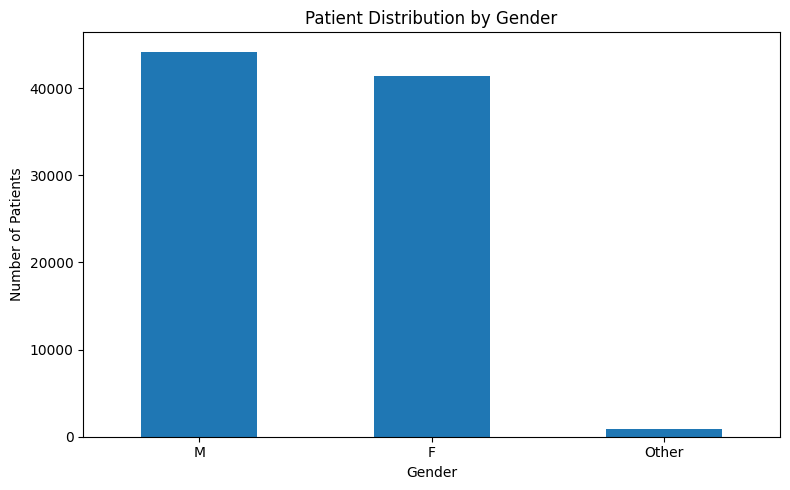

In [3]:
gender_count = patients["gender"].value_counts()

plt.figure(figsize=(8, 5))
gender_count.plot(kind="bar")

plt.title("Patient Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Q2. Which states have the highest number of patients?

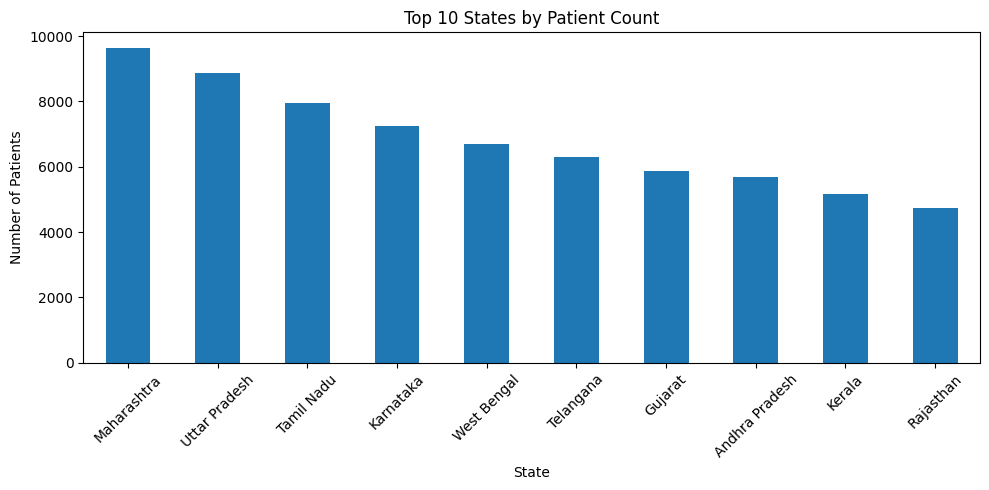

In [4]:
state_count = patients["state"].value_counts().head(10)

plt.figure(figsize=(10, 5))
state_count.plot(kind="bar")

plt.title("Top 10 States by Patient Count")
plt.xlabel("State")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q3. What is the age distribution of patients?

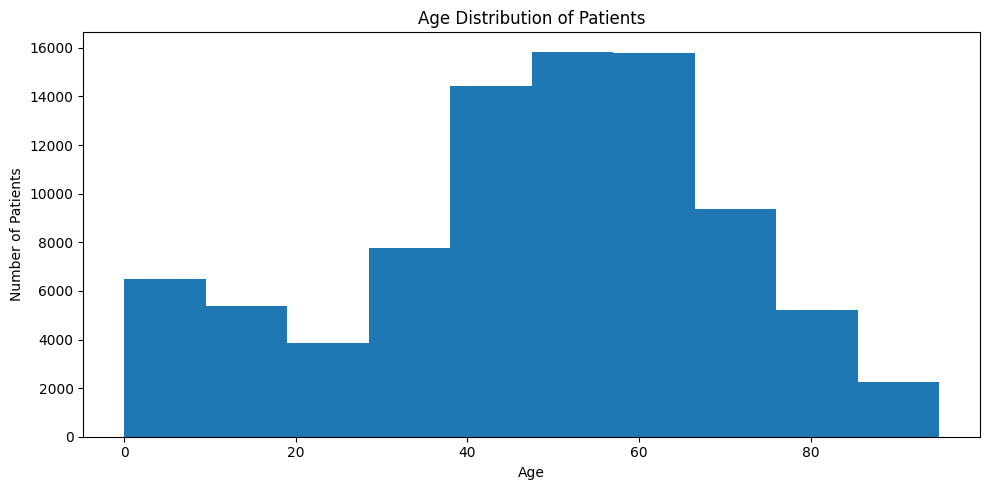

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    patients["age"].dropna(),
    bins=10
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

Q4. Which admission types are most common?

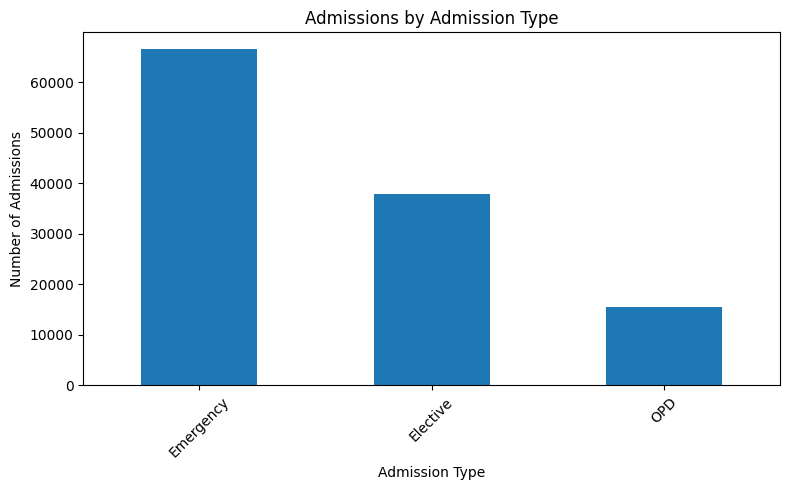

In [6]:
admission_type_count = admissions["admit_type"].value_counts()

plt.figure(figsize=(8, 5))
admission_type_count.plot(kind="bar")

plt.title("Admissions by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q5. Which ward types handle the most admissions?

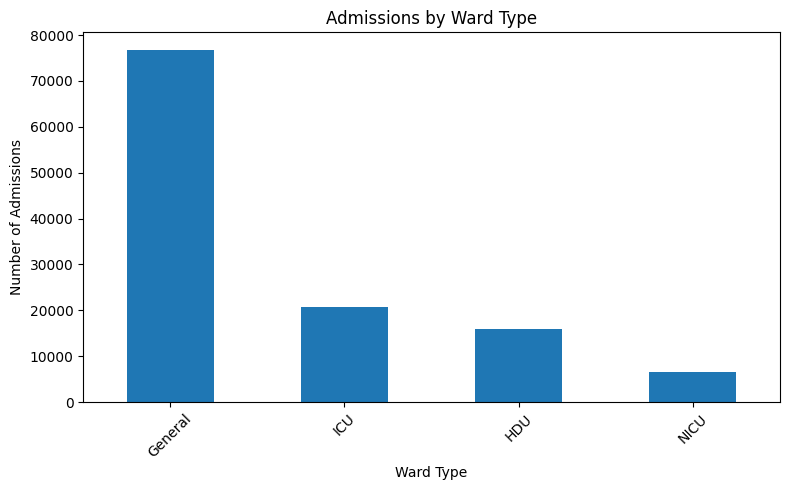

In [7]:
ward_count = admissions["ward_type"].value_counts()

plt.figure(figsize=(8, 5))
ward_count.plot(kind="bar")

plt.title("Admissions by Ward Type")
plt.xlabel("Ward Type")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q6. How do admissions change over time?

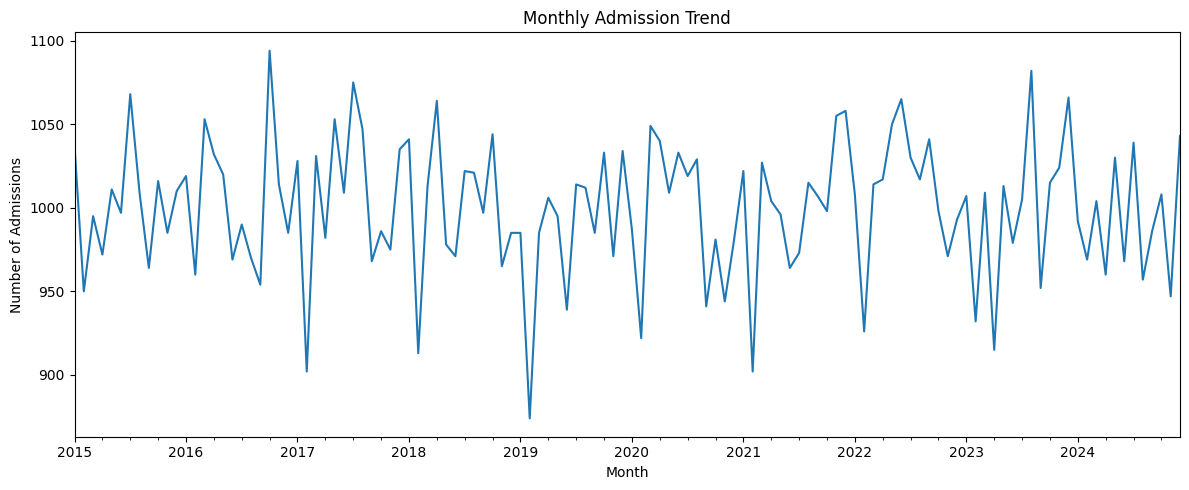

In [9]:
monthly_admissions = (
    admissions
    .set_index("admit_date")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 5))
monthly_admissions.plot(kind="line")

plt.title("Monthly Admission Trend")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.tight_layout()
plt.show()

Q7. Which discharge types are most common?

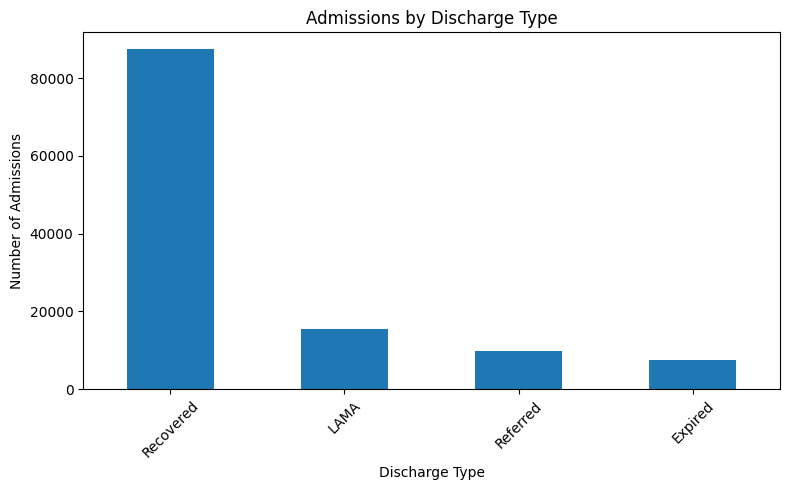

In [10]:
discharge_count = admissions["discharge_type"].value_counts()

plt.figure(figsize=(8, 5))
discharge_count.plot(kind="bar")

plt.title("Admissions by Discharge Type")
plt.xlabel("Discharge Type")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q8. Which ward types have the highest average length of stay?

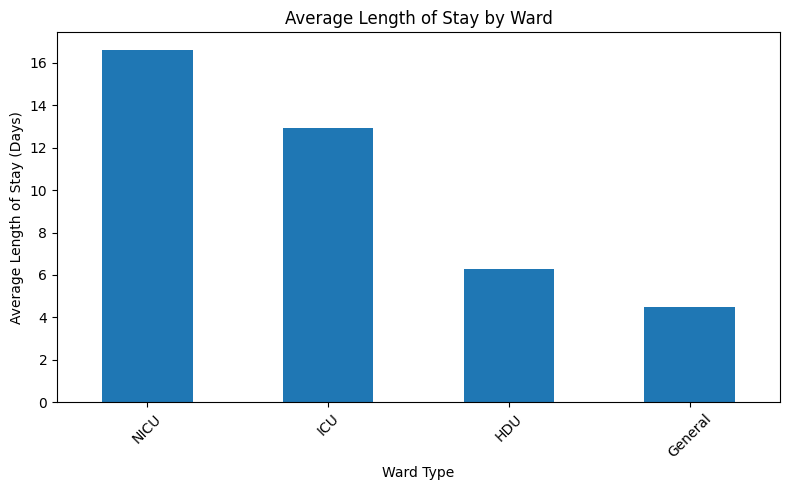

In [11]:
avg_los = (
    admissions
    .groupby("ward_type")["los_days"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
avg_los.plot(kind="bar")

plt.title("Average Length of Stay by Ward")
plt.xlabel("Ward Type")
plt.ylabel("Average Length of Stay (Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q9. Which admission types generate the highest average billing?

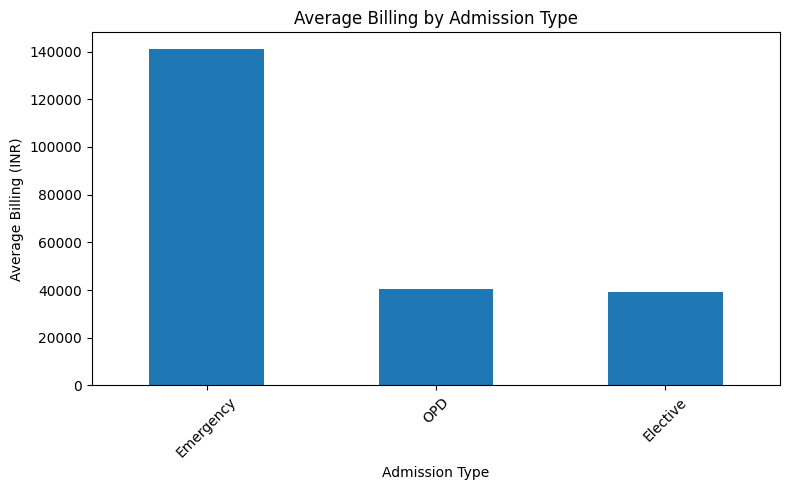

In [12]:
avg_billing = (
    hospital_data
    .groupby("admit_type")["total_cost_inr"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
avg_billing.plot(kind="bar")

plt.title("Average Billing by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Average Billing (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q10. Which cost categories contribute the most billing?

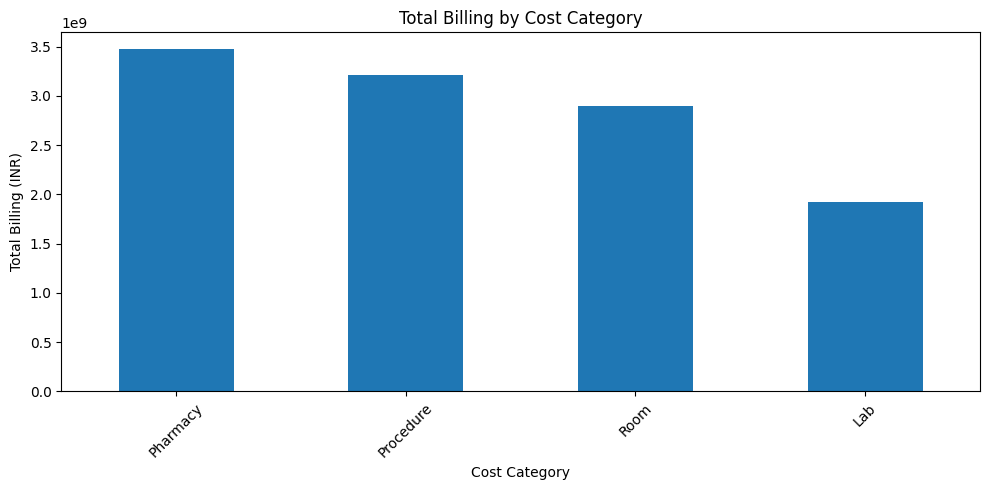

In [13]:
cost_category = (
    billing
    .groupby("cost_category")["total_cost_inr"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
cost_category.plot(kind="bar")

plt.title("Total Billing by Cost Category")
plt.xlabel("Cost Category")
plt.ylabel("Total Billing (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q11. How much government subsidy is provided across cost categories?

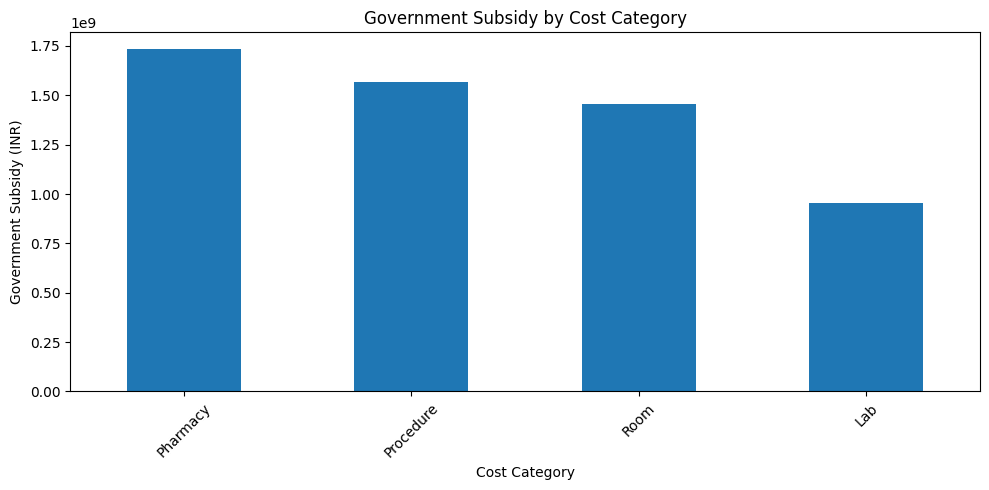

In [14]:
subsidy = (
    billing
    .groupby("cost_category")["govt_subsidy_inr"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
subsidy.plot(kind="bar")

plt.title("Government Subsidy by Cost Category")
plt.xlabel("Cost Category")
plt.ylabel("Government Subsidy (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q12. Which insurance types have the highest average out-of-pocket cost?

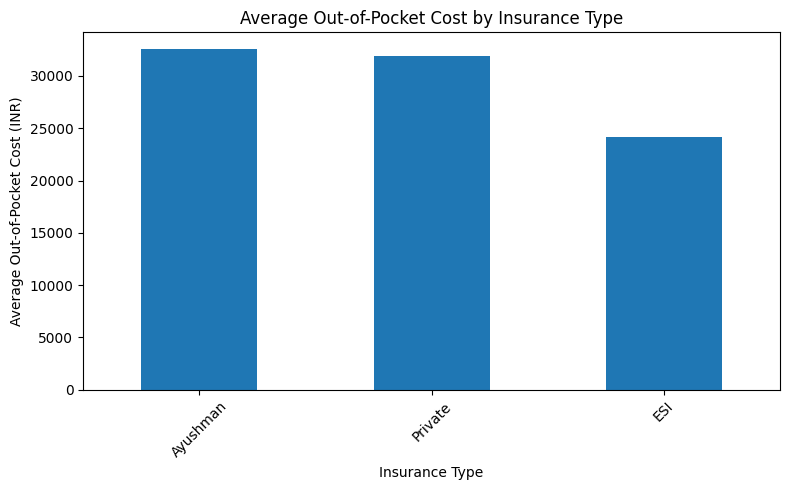

In [15]:
avg_out_of_pocket = (
    hospital_data
    .groupby("insurance_type")["out_of_pocket_inr"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
avg_out_of_pocket.plot(kind="bar")

plt.title("Average Out-of-Pocket Cost by Insurance Type")
plt.xlabel("Insurance Type")
plt.ylabel("Average Out-of-Pocket Cost (INR)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q13. Is there a relationship between length of stay and total billing?

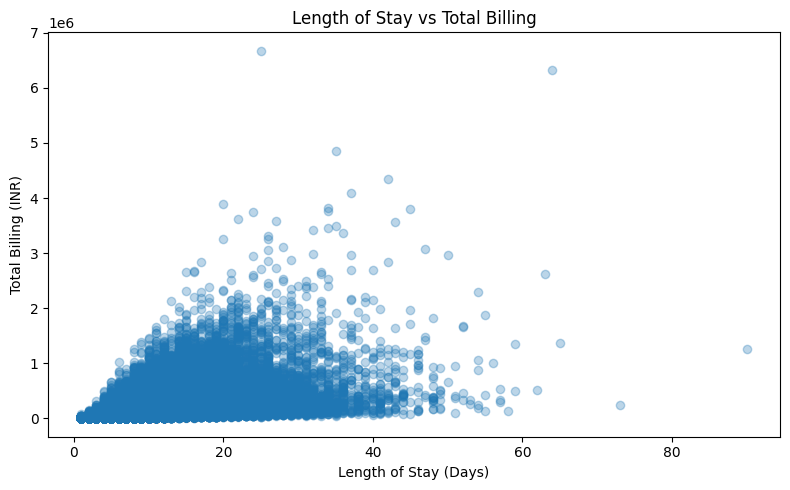

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    hospital_data["los_days"],
    hospital_data["total_cost_inr"],
    alpha=0.3
)

plt.title("Length of Stay vs Total Billing")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Total Billing (INR)")
plt.tight_layout()
plt.show()

Q14. Which diagnosis categories are most common?

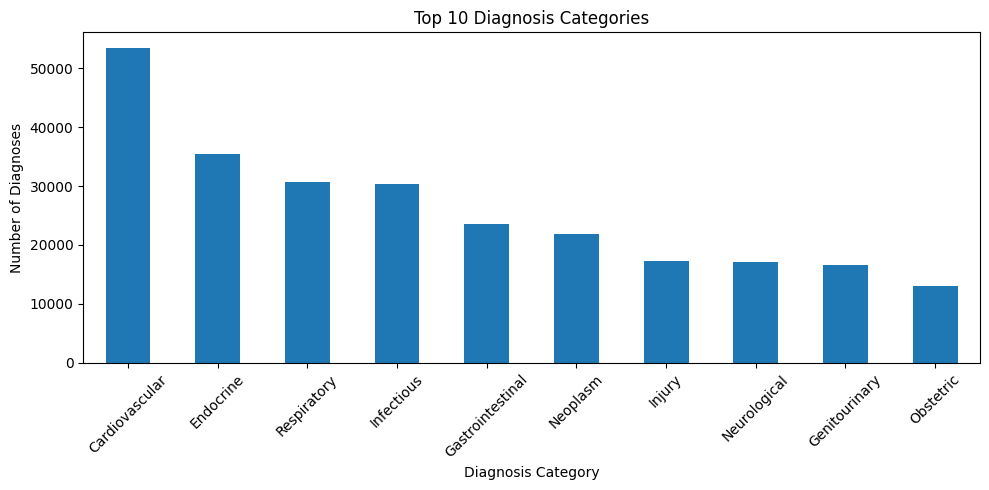

In [17]:
diagnosis_count = diagnoses["diag_category"].value_counts().head(10)

plt.figure(figsize=(10, 5))
diagnosis_count.plot(kind="bar")

plt.title("Top 10 Diagnosis Categories")
plt.xlabel("Diagnosis Category")
plt.ylabel("Number of Diagnoses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Q15. Which hospitals have the highest number of admissions?

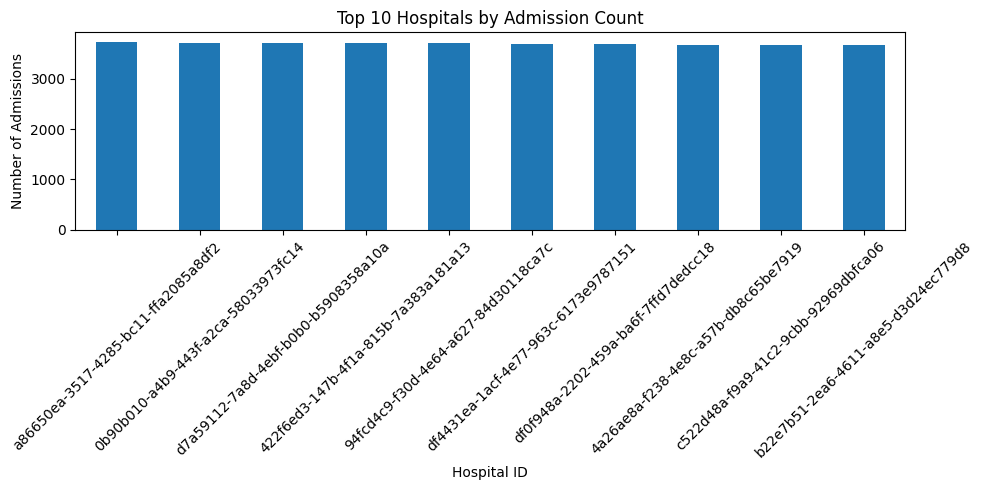

In [18]:
hospital_count = admissions["hospital_id"].value_counts().head(10)

plt.figure(figsize=(10, 5))
hospital_count.plot(kind="bar")

plt.title("Top 10 Hospitals by Admission Count")
plt.xlabel("Hospital ID")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()